<a href="https://colab.research.google.com/github/Valeria1100/Confiabilidad-y-planeaci-n-de-capacidad-de-un-servicio-de-inferencia-de-IA./blob/main/Punto%20A%20y%20B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# ==============================================================================
# CELDA 0: PARÁMETROS PERSONALIZADOS DEL GRUPO (Sección 3 y Entregable E1)
# ==============================================================================
# Integrantes Grupo 5:
# Pareja 1: Valeria Noreña (1013605786) + María Pachón (1014990415)
# Pareja 2: Thomas Bacca (1018436144) + Sara León (1016948827)

C1 = 1013605786 + 1014990415   # 2028596201
C2 = 1018436144 + 1016948827   # 2035384971
S = C1 + C2                    # 4063981172

# Única fuente de aleatoriedad permitida en todo el notebook
rng = np.random.default_rng(S)

# Parámetros derivados de S
tau = 180 + 10 * (S % 9)                      # 230 ms (Umbral SLO)
eps = 0.01 * (1 + (S % 3))                    # 0.03 (Proporción máxima tolerada L > tau)
conf_map = {0: 0.90, 1: 0.95, 2: 0.99}
confianza = conf_map[S % 3]                   # 0.99 (Nivel de confianza 1 - alpha)
alpha = 1.0 - confianza                       # 0.01 (Nivel de significancia)
g = 1.4 + 0.1 * (S % 7)                       # 2.0 (Factor de crecimiento proyección)
t1 = 180 + 10 * (S % 5)                       # 200 KB (Frontera tamaño pequeña/mediana)
t2 = 400 + 25 * (S % 5)                       # 450 KB (Frontera tamaño mediana/grande)
pi = (4 + (S % 6)) / 1000.0                   # 0.006 (Prevalencia incidentes)
k_max = 4 + (S % 5)                           # 6 (Máximo falsas alarmas/día)
r = S % 6                                     # 2 (Desplazamiento ítem B4)
N = 10 + (S % 11)                             # 19 (Solicitudes consecutivas ítem C4)

print(f"C1 = {C1} | C2 = {C2} | S = {S}")
print(f"tau = {tau} ms | eps = {eps} | 1-alpha = {confianza} | g = {g:.1f}")
print(f"t1 = {t1} KB | t2 = {t2} KB | pi = {pi} | k_max = {k_max} | r = {r} | N = {N}")

C1 = 2028596201 | C2 = 2035384971 | S = 4063981172
tau = 230 ms | eps = 0.03 | 1-alpha = 0.99 | g = 2.0
t1 = 200 KB | t2 = 450 KB | pi = 0.006 | k_max = 6 | r = 2 | N = 19


In [2]:
# ==============================================================================
# PUNTO A1: AUDITORÍA Y PREPARACIÓN DE LOS DATOS
# ==============================================================================
df_raw = pd.read_csv('solicitudes.csv')
print(f"Total de registros crudos: {len(df_raw)}")

# 1. Detección y eliminación de registros duplicados exactos
n_dup = df_raw.duplicated(keep='first').sum()
df = df_raw.drop_duplicates(keep='first').copy()

# 2. Detección y corrección de error de escala en tam_kb (reportados en Bytes en vez de KB)
mask_bytes = df['tam_kb'] > 5000
n_bytes = mask_bytes.sum()
df.loc[mask_bytes, 'tam_kb'] = df.loc[mask_bytes, 'tam_kb'] / 1024.0

# 3. Tratamiento de valores faltantes (NaN) usando la arquitectura física (Sección 4.1)
n_nan_total = df.isna().any(axis=1).sum()
# Si cache_hit == 1, no usa GPU (gpu_ms = 0) y no hace cola (red_ms = latencia_ms)
mask_rec_gpu = (df['cache_hit'] == 1) & (df['gpu_ms'].isna())
mask_rec_red = (df['cache_hit'] == 1) & (df['red_ms'].isna())
df.loc[mask_rec_gpu, 'gpu_ms'] = 0.0
df.loc[mask_rec_red, 'red_ms'] = df.loc[mask_rec_red, 'latencia_ms']
# En cache_hit == 0, L = red + cola + G queda subdeterminada -> se excluyen
df = df.dropna(subset=['red_ms', 'gpu_ms']).copy()

# 4. Exclusión de latencias centinela negativas (latencia_ms == -1.0)
n_lat_neg = (df['latencia_ms'] <= 0).sum()
df = df[df['latencia_ms'] > 0].copy()

# 5. Exclusión de violaciones físicas donde L < red_ms + gpu_ms (tolerancia 0.02 ms por redondeo)
mask_fisica = df['latencia_ms'] + 0.02 < (df['red_ms'] + df['gpu_ms'])
n_fisica = mask_fisica.sum()
df = df[~mask_fisica].copy()

print(f"Duplicados eliminados: {n_dup}")
print(f"Tamaños corregidos (Bytes -> KB): {n_bytes}")
print(f"NaN reconstruidos (cache_hit=1): {mask_rec_gpu.sum() + mask_rec_red.sum()} | NaN excluidos (cache_hit=0): {n_nan_total - (mask_rec_gpu.sum() + mask_rec_red.sum())}")
print(f"Latencias centinela (<= 0) excluidas: {n_lat_neg}")
print(f"Violaciones físicas (L < red + G) excluidas: {n_fisica}")
print(f"Total de registros limpios conservados: {len(df)} ({len(df)/len(df_raw)*100:.2f}%)")

Total de registros crudos: 32472
Duplicados eliminados: 97
Tamaños corregidos (Bytes -> KB): 48
NaN reconstruidos (cache_hit=1): 24 | NaN excluidos (cache_hit=0): 40
Latencias centinela (<= 0) excluidas: 97
Violaciones físicas (L < red + G) excluidas: 64
Total de registros limpios conservados: 32174 (99.08%)


In [3]:
# ==============================================================================
# PUNTO A2: ESTACIONARIEDAD, DETECCIÓN DE PUNTOS DE CAMBIO Y SENSIBILIDAD
# ==============================================================================
# 1. Prueba CUSUM con permutaciones de Montecarlo sobre bloques de 10 s (120 bloques)
df['bloque_10s'] = (df['t_llegada_s'] // 10).astype(int)
tasa_10s = df.groupby('bloque_10s')['id_solicitud'].count().reindex(range(120), fill_value=0).values / 10.0

cusum = np.cumsum(tasa_10s - np.mean(tasa_10s))
R_obs = np.max(cusum) - np.min(cusum)

R_perm = np.array([
    np.ptp(np.cumsum(rng.permutation(tasa_10s) - np.mean(tasa_10s)))
    for _ in range(5000)
])
p_cusum = np.mean(R_perm >= R_obs)
print(f"Prueba CUSUM global: R_obs = {R_obs:.2f}, p-valor = {p_cusum:.6f}")

# 2. Búsqueda óptima de puntos de cambio [ta, tb) mediante devianza Poisson en conteos de 1 s
df['sec'] = df['t_llegada_s'].astype(int)
conteos_1s = df.groupby('sec')['id_solicitud'].count().reindex(range(1200), fill_value=0).values

def poisson_deviance(y):
    m = np.mean(y)
    if len(y) == 0 or m == 0:
        return 0.0
    y_pos = y[y > 0]
    return 2.0 * (np.sum(y_pos * np.log(y_pos / m)) - np.sum(y) + len(y) * m)

best_dev = np.inf
ta_opt, tb_opt = None, None
for ta in range(350, 420):
    for tb in range(550, 620):
        seg_est = np.concatenate([conteos_1s[:ta], conteos_1s[tb:]])
        seg_ano = conteos_1s[ta:tb]
        dev = poisson_deviance(seg_est) + poisson_deviance(seg_ano)
        if dev < best_dev:
            best_dev = dev
            ta_opt, tb_opt = ta, tb

dev_null = poisson_deviance(conteos_1s)
print(f"Devianza 1 régimen: {dev_null:.2f} | Devianza 2 regímenes [{ta_opt}s, {tb_opt}s): {best_dev:.2f}")
print(f"Estadístico LRT (reducción devianza): {dev_null - best_dev:.2f}")

# 3. Verificación de equivalencia entre Pre-anomalía [0, 397) y Post-anomalía [577, 1200)
seg_pre = df[df['t_llegada_s'] < ta_opt]
seg_post = df[df['t_llegada_s'] >= tb_opt]

_, p_tasa = stats.mannwhitneyu(conteos_1s[:ta_opt], conteos_1s[tb_opt:])
ks_stat, p_ks = stats.ks_2samp(seg_pre['latencia_ms'], seg_post['latencia_ms'])

n1, k1 = len(seg_pre), (seg_pre['intentos'] > 1).sum()
n2, k2 = len(seg_post), (seg_post['intentos'] > 1).sum()
p_pool = (k1 + k2) / (n1 + n2)
z_reint = (k1/n1 - k2/n2) / np.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
p_reint = 2 * (1 - stats.norm.cdf(abs(z_reint)))

print(f"Equivalencia Pre vs Post -> Mann-Whitney tasa p={p_tasa:.4f} | KS latencia p={p_ks:.4f} | Z reintentos p={p_reint:.4f}")

# 4. Etiquetado definitivo del régimen estable y análisis de sensibilidad
df['regimen'] = np.where((df['t_llegada_s'] >= ta_opt) & (df['t_llegada_s'] < tb_opt),
                         'Inestable', 'Estable')
df_estable = df[df['regimen'] == 'Estable'].copy()
print(f"Solicitudes en Régimen Estable: {len(df_estable)} (duración = {ta_opt + (1200 - tb_opt)} s)")

Prueba CUSUM global: R_obs = 527.68, p-valor = 0.000000
Devianza 1 régimen: 6806.61 | Devianza 2 regímenes [397s, 576s): 1212.54
Estadístico LRT (reducción devianza): 5594.07
Equivalencia Pre vs Post -> Mann-Whitney tasa p=0.9940 | KS latencia p=0.9583 | Z reintentos p=0.1621
Solicitudes en Régimen Estable: 22040 (duración = 1021 s)


,Régimen,Versión,Variable,n,Media,Mediana,DE,IQR,Asimetría,Curtosis_exceso
0,Estable,A,latencia_ms,10963,66.022,52.00,49.141,57.950,2.020,6.691
1,Estable,A,gpu_ms,10963,35.530,23.50,45.146,52.230,2.314,9.137
2,Estable,A,red_ms,10963,26.438,26.40,3.918,5.260,0.005,0.024
3,Estable,A,tam_kb,10963,240.946,201.85,170.787,205.800,1.462,3.209
4,Estable,B,latencia_ms,11077,60.645,48.48,43.388,49.070,2.323,9.535
5,Estable,B,gpu_ms,11077,29.806,19.59,37.520,44.200,2.357,9.645
6,Estable,B,red_ms,11077,26.412,26.45,3.855,5.200,0.004,0.034
7,Estable,B,tam_kb,11077,239.108,200.04,169.048,205.380,1.434,2.959
8,Inestable,A,latencia_ms,5043,171.951,106.72,180.716,218.955,1.479,1.767
9,Inestable,A,gpu_ms,5043,34.329,23.04,41.958,51.780,1.964,5.645


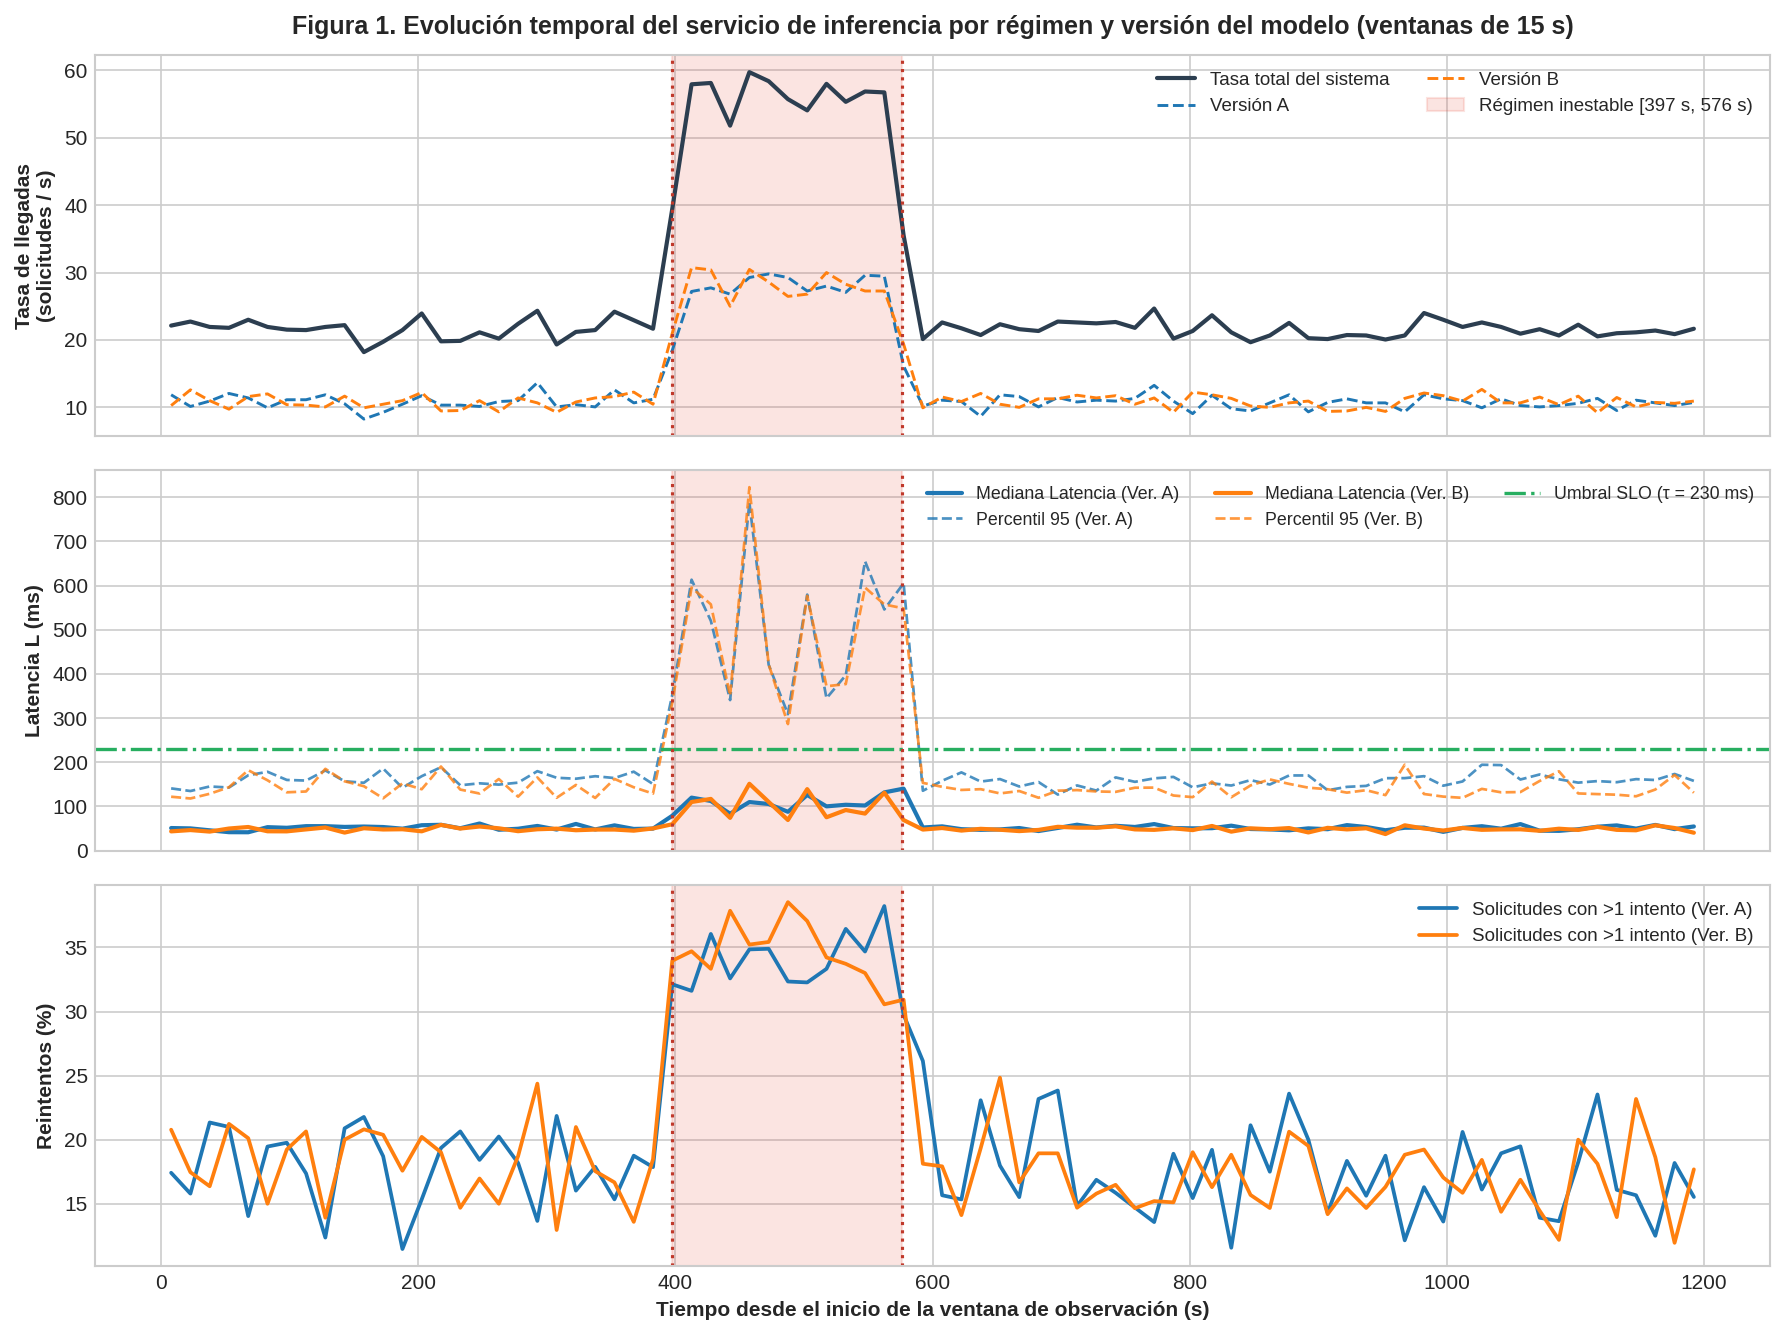

In [4]:
# ==============================================================================
# PUNTO A3: ESTADÍSTICA DESCRIPTIVA Y FIGURA 1 (EVOLUCIÓN TEMPORAL)
# ==============================================================================
vars_interes = ['latencia_ms', 'gpu_ms', 'red_ms', 'tam_kb']
filas_a3 = []

for reg in ['Estable', 'Inestable']:
    for ver in ['A', 'B']:
        sub = df[(df['regimen'] == reg) & (df['version'] == ver)]
        for var in vars_interes:
            s = sub[var]
            filas_a3.append({
                'Régimen': reg,
                'Versión': ver,
                'Variable': var,
                'n': len(s),
                'Media': s.mean(),
                'Mediana': s.median(),
                'DE': s.std(ddof=1),
                'IQR': s.quantile(0.75) - s.quantile(0.25),
                'Asimetría': stats.skew(s, bias=False),
                'Curtosis_exceso': stats.kurtosis(s, fisher=True, bias=False)
            })

tabla_a3 = pd.DataFrame(filas_a3)
display(tabla_a3.round(3))

# Figura 1: Evolución temporal en ventanas de 15 s
df['v15'] = (df['t_llegada_s'] // 15).astype(int) * 15 + 7.5
ts = df.groupby(['v15', 'version']).agg(
    tasa=('id_solicitud', lambda x: len(x) / 15.0),
    lat_med=('latencia_ms', 'median'),
    lat_p95=('latencia_ms', lambda x: np.percentile(x, 95)),
    reint=('intentos', lambda x: (x > 1).mean() * 100)
).reset_index()
ts_tot = df.groupby('v15').agg(tasa_tot=('id_solicitud', lambda x: len(x) / 15.0)).reset_index()

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, dpi=150)
colores = {'A': '#1f77b4', 'B': '#ff7f0e'}

# Panel 1: Tasa de llegadas
axes[0].plot(ts_tot['v15'], ts_tot['tasa_tot'], color='#2c3e50', lw=2, label='Tasa total del sistema')
for ver in ['A', 'B']:
    sub_v = ts[ts['version'] == ver]
    axes[0].plot(sub_v['v15'], sub_v['tasa'], '--', lw=1.4, color=colores[ver], label=f'Versión {ver}')
axes[0].axvspan(ta_opt, tb_opt, color='#e74c3c', alpha=0.15, label=f'Régimen inestable [{ta_opt} s, {tb_opt} s)')
axes[0].axvline(ta_opt, color='#c0392b', ls=':', lw=1.5)
axes[0].axvline(tb_opt, color='#c0392b', ls=':', lw=1.5)
axes[0].set_ylabel('Tasa de llegadas\n(solicitudes / s)', fontsize=10, fontweight='bold')
axes[0].set_title('Figura 1. Evolución temporal del servicio de inferencia por régimen y versión del modelo (ventanas de 15 s)',
                  fontsize=12, fontweight='bold', pad=10)
axes[0].legend(loc='upper right', ncol=2, fontsize=9)

# Panel 2: Latencia mediana y P95
for ver in ['A', 'B']:
    sub_v = ts[ts['version'] == ver]
    axes[1].plot(sub_v['v15'], sub_v['lat_med'], lw=2, color=colores[ver], label=f'Mediana Latencia (Ver. {ver})')
    axes[1].plot(sub_v['v15'], sub_v['lat_p95'], '--', lw=1.3, color=colores[ver], alpha=0.8, label=f'Percentil 95 (Ver. {ver})')
axes[1].axhline(tau, color='#27ae60', ls='-.', lw=1.6, label=f'Umbral SLO (τ = {tau} ms)')
axes[1].axvspan(ta_opt, tb_opt, color='#e74c3c', alpha=0.15)
axes[1].axvline(ta_opt, color='#c0392b', ls=':', lw=1.5)
axes[1].axvline(tb_opt, color='#c0392b', ls=':', lw=1.5)
axes[1].set_ylabel('Latencia L (ms)', fontsize=10, fontweight='bold')
axes[1].legend(loc='upper right', ncol=3, fontsize=8.5)

# Panel 3: Reintentos
for ver in ['A', 'B']:
    sub_v = ts[ts['version'] == ver]
    axes[2].plot(sub_v['v15'], sub_v['reint'], lw=1.8, color=colores[ver], label=f'Solicitudes con >1 intento (Ver. {ver})')
axes[2].axvspan(ta_opt, tb_opt, color='#e74c3c', alpha=0.15)
axes[2].axvline(ta_opt, color='#c0392b', ls=':', lw=1.5)
axes[2].axvline(tb_opt, color='#c0392b', ls=':', lw=1.5)
axes[2].set_ylabel('Reintentos (%)', fontsize=10, fontweight='bold')
axes[2].set_xlabel('Tiempo desde el inicio de la ventana de observación (s)', fontsize=10, fontweight='bold')
axes[2].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('figura_1_evolucion_temporal.png', dpi=150)
plt.show()

Tasa estimada lambda_hat = 21.58668 req/s | IC 99%: [21.21398, 21.96405]
[Vía 1 - Conteos 1s] Media=21.5867, Var=21.0976, Var/Media=0.9773 (p=0.6165)
[Vía 1 - Chi2 GoF]   chi2=13.1225, gl=20, p-valor=0.8721
[Vía 2 - Inter-llegadas] Media=46.321 ms, DE=46.411 ms, CV=1.0020
[Vía 2 - KS Exponencial] D=0.00561, p-valor=0.4889 | ACF lag-1=0.00588


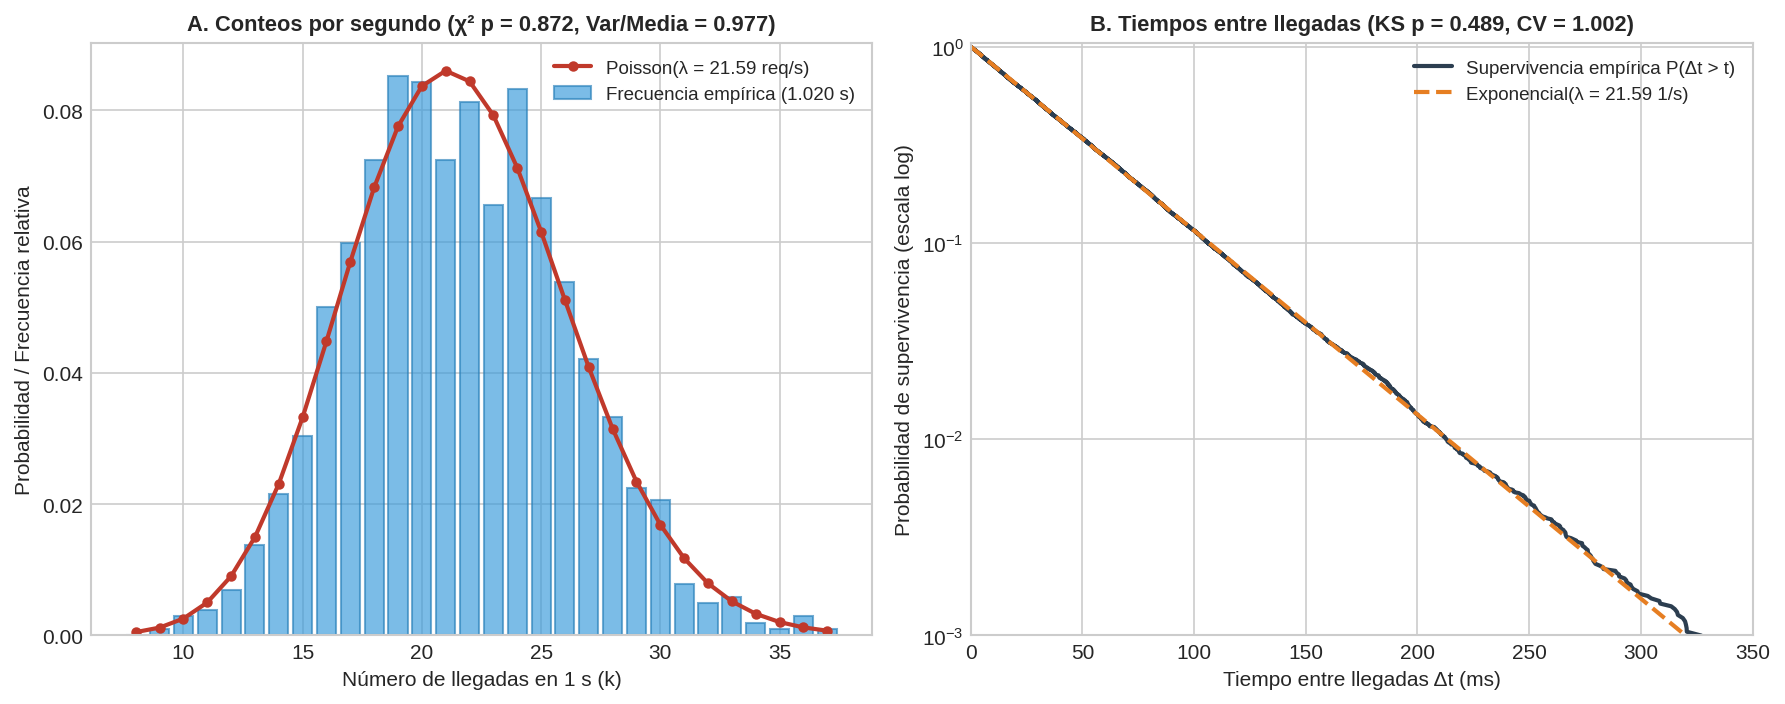

In [5]:
# ==============================================================================
# PUNTO B1: MODELADO Y VALIDACIÓN DEL PROCESO DE LLEGADAS (RÉGIMEN ESTABLE)
# ==============================================================================
df_est = df[df['regimen'] == 'Estable'].sort_values('t_llegada_s').reset_index(drop=True)
T_estable = ta_opt + (1200 - tb_opt)  # 1020 s
n_est = len(df_est)
lam_hat = n_est / T_estable

# Intervalo de confianza exacto al (1 - alpha) = 99% para lambda
ci_low = stats.chi2.ppf(alpha / 2, 2 * n_est) / (2 * T_estable)
ci_high = stats.chi2.ppf(1 - alpha / 2, 2 * (n_est + 1)) / (2 * T_estable)

print(f"Tasa estimada lambda_hat = {lam_hat:.5f} req/s | IC {int(confianza*100)}%: [{ci_low:.5f}, {ci_high:.5f}]")

# --- VÍA 1: Conteos en ventanas disjuntas de 1 s ---
secs_est = list(range(0, ta_opt)) + list(range(tb_opt, 1200))
df_est['sec'] = df_est['t_llegada_s'].astype(int)
conteos_1s = df_est.groupby('sec')['id_solicitud'].count().reindex(secs_est, fill_value=0).values

mean_c = np.mean(conteos_1s)
var_c = np.var(conteos_1s, ddof=1)
disp_index = var_c / mean_c
chi2_disp = (len(conteos_1s) - 1) * disp_index
p_disp = 2 * min(stats.chi2.cdf(chi2_disp, len(conteos_1s) - 1),
                 1 - stats.chi2.cdf(chi2_disp, len(conteos_1s) - 1))

# Bondad de ajuste Chi-cuadrado (agrupando colas k < 12 y k >= 32 para E_i >= 5)
k_max_val = int(conteos_1s.max())
probs = stats.poisson.pmf(np.arange(k_max_val + 1), lam_hat)
probs[-1] += 1.0 - np.sum(probs)
obs_full = np.bincount(conteos_1s, minlength=k_max_val + 1)
exp_full = probs * len(conteos_1s)

obs_g = np.array([obs_full[:12].sum()] + list(obs_full[12:32]) + [obs_full[32:].sum()])
exp_g = np.array([exp_full[:12].sum()] + list(exp_full[12:32]) + [exp_full[32:].sum()])

chi2_gof = np.sum((obs_g - exp_g) ** 2 / exp_g)
dof_gof = len(obs_g) - 1 - 1
p_gof = 1 - stats.chi2.cdf(chi2_gof, dof_gof)

print(f"[Vía 1 - Conteos 1s] Media={mean_c:.4f}, Var={var_c:.4f}, Var/Media={disp_index:.4f} (p={p_disp:.4f})")
print(f"[Vía 1 - Chi2 GoF]   chi2={chi2_gof:.4f}, gl={dof_gof}, p-valor={p_gof:.4f}")

# --- VÍA 2: Tiempos entre llegadas (sin cruzar la frontera de la anomalía) ---
dt_pre = np.diff(df_est[df_est['t_llegada_s'] < ta_opt]['t_llegada_s'].values)
dt_post = np.diff(df_est[df_est['t_llegada_s'] >= tb_opt]['t_llegada_s'].values)
dt_all = np.concatenate([dt_pre, dt_post])

mean_dt = np.mean(dt_all)
std_dt = np.std(dt_all, ddof=1)
cv_dt = std_dt / mean_dt
ks_exp, p_ks_exp = stats.kstest(dt_all, 'expon', args=(0, 1.0 / lam_hat))
acf_lag1 = np.corrcoef(dt_all[:-1], dt_all[1:])[0, 1]

print(f"[Vía 2 - Inter-llegadas] Media={mean_dt*1000:.3f} ms, DE={std_dt*1000:.3f} ms, CV={cv_dt:.4f}")
print(f"[Vía 2 - KS Exponencial] D={ks_exp:.5f}, p-valor={p_ks_exp:.4f} | ACF lag-1={acf_lag1:.5f}")

# --- Figura diagnóstica B1 ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), dpi=150)

k_plot = np.arange(8, 38)
obs_rel = np.array([(conteos_1s == k).mean() for k in k_plot])
pmf_theo = stats.poisson.pmf(k_plot, lam_hat)

axes[0].bar(k_plot, obs_rel, color='#3498db', alpha=0.65, edgecolor='#2980b9', label='Frecuencia empírica (1.020 s)')
axes[0].plot(k_plot, pmf_theo, 'o-', color='#c0392b', lw=2, markersize=4, label=f'Poisson(λ = {lam_hat:.2f} req/s)')
axes[0].set_title(f'A. Conteos por segundo (χ² p = {p_gof:.3f}, Var/Media = {disp_index:.3f})', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Número de llegadas en 1 s (k)', fontsize=10)
axes[0].set_ylabel('Probabilidad / Frecuencia relativa', fontsize=10)
axes[0].legend(fontsize=9)

dt_sorted = np.sort(dt_all)
surv_emp = 1.0 - np.arange(1, len(dt_sorted) + 1) / (len(dt_sorted) + 1)
surv_theo = np.exp(-lam_hat * dt_sorted)

axes[1].semilogy(dt_sorted * 1000, surv_emp, color='#2c3e50', lw=2, label='Supervivencia empírica P(Δt > t)')
axes[1].semilogy(dt_sorted * 1000, surv_theo, '--', color='#e67e22', lw=2, label=f'Exponencial(λ = {lam_hat:.2f} 1/s)')
axes[1].set_title(f'B. Tiempos entre llegadas (KS p = {p_ks_exp:.3f}, CV = {cv_dt:.3f})', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Tiempo entre llegadas Δt (ms)', fontsize=10)
axes[1].set_ylabel('Probabilidad de supervivencia (escala log)', fontsize=10)
axes[1].set_xlim(0, 350)
axes[1].set_ylim(1e-3, 1.05)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('figura_b1_proceso_llegadas.png', dpi=150)
plt.show()

In [6]:
# ==============================================================================
# PUNTO B2: DESCOMPOSICIÓN POR VERSIÓN Y FLUJO EFECTIVO AL POOL DE GPUs
# ==============================================================================
def ic_poisson(k, T, alpha=0.01):
    low = stats.chi2.ppf(alpha / 2, 2 * k) / (2 * T)
    high = stats.chi2.ppf(1 - alpha / 2, 2 * (k + 1)) / (2 * T)
    return low, high

# Subconjuntos en régimen estable
df_A = df_est[df_est['version'] == 'A']
df_B = df_est[df_est['version'] == 'B']
df_gpu = df_est[df_est['cache_hit'] == 0]
df_gpu_A = df_gpu[df_gpu['version'] == 'A']
df_gpu_B = df_gpu[df_gpu['version'] == 'B']

# Pruebas de balanceo 50/50, independencia entre A y B, e independencia de caché
p_binom = stats.binomtest(len(df_A), len(df_est), p=0.5).pvalue
ver_bin = (df_est['version'] == 'B').astype(int).values
acf_ver = np.corrcoef(ver_bin[:-1], ver_bin[1:])[0, 1]

c_A = df_A.groupby('sec')['id_solicitud'].count().reindex(secs_est, fill_value=0).values
c_B = df_B.groupby('sec')['id_solicitud'].count().reindex(secs_est, fill_value=0).values
corr_AB, p_corr_AB = stats.pearsonr(c_A, c_B)

_, p_cache_ver, _, _ = stats.chi2_contingency([
    [(df_A['cache_hit'] == 1).sum(), (df_A['cache_hit'] == 0).sum()],
    [(df_B['cache_hit'] == 1).sum(), (df_B['cache_hit'] == 0).sum()]
])

print(f"Balanceo A/B (p=0.5): p-valor = {p_binom:.4f} | ACF lag-1 versión = {acf_ver:.5f}")
print(f"Correlación conteos N_A vs N_B: r = {corr_AB:.5f} (p = {p_corr_AB:.4f})")
print(f"Independencia cache_hit vs versión: p-valor Chi2 = {p_cache_ver:.4f}\n")

# Tabla resumen B2
flujos = [
    ('Total al balanceador', df_est),
    ('Versión A (total)', df_A),
    ('Versión B (total)', df_B),
    ('Total efectivo a GPU (cache_hit=0)', df_gpu),
    ('Versión A efectiva a GPU', df_gpu_A),
    ('Versión B efectiva a GPU', df_gpu_B),
]

filas_b2 = []
for nombre, sub in flujos:
    n_f = len(sub)
    lam_f = n_f / T_estable
    low_f, high_f = ic_poisson(n_f, T_estable, alpha)
    cnt_f = sub.groupby('sec')['id_solicitud'].count().reindex(secs_est, fill_value=0).values
    disp_f = np.var(cnt_f, ddof=1) / np.mean(cnt_f)
    filas_b2.append({
        'Flujo': nombre,
        'n': n_f,
        'Proporción (%)': (n_f / len(df_est)) * 100,
        'Tasa_hat (req/s)': lam_f,
        'IC99_inf': low_f,
        'IC99_sup': high_f,
        'Indice_Dispersion': disp_f
    })

tabla_b2 = pd.DataFrame(filas_b2)
display(tabla_b2.round(4))

Balanceo A/B (p=0.5): p-valor = 0.4466 | ACF lag-1 versión = -0.00897
Correlación conteos N_A vs N_B: r = -0.01721 (p = 0.5828)
Independencia cache_hit vs versión: p-valor Chi2 = 0.7348



,Flujo,n,Proporción (%),Tasa_hat (req/s),IC99_inf,IC99_sup,Indice_Dispersion
0,Total al balanceador,22040,100.0000,21.5867,21.2140,21.9640,0.9773
1,Versión A (total),10963,49.7414,10.7375,10.4752,11.0045,1.0098
2,Versión B (total),11077,50.2586,10.8492,10.5855,11.1175,0.9793
3,Total efectivo a GPU (cache_hit=0),14307,64.9138,14.0127,13.7128,14.3173,0.9964
4,Versión A efectiva a GPU,7104,32.2323,6.9579,6.7471,7.1734,1.0462
5,Versión B efectiva a GPU,7203,32.6815,7.0548,6.8426,7.2718,0.9543


In [7]:
# ==============================================================================
# PUNTO B3: DISTRIBUCIÓN GEOMÉTRICA DE INTENTOS Y PRUEBA DE INDEPENDENCIA
# ==============================================================================
from scipy.optimize import minimize_scalar

filas_b3 = []
for reg in ['Estable', 'Inestable']:
    for ver in ['A', 'B']:
        sub = df[(df['regimen'] == reg) & (df['version'] == ver)]
        k = sub['intentos'].values
        n = len(k)
        c1, c2, c3 = np.sum(k == 1), np.sum(k == 2), np.sum(k == 3)

        # Estimador MLE Geométrica estándar sobre {1, 2, 3, ...}: p_hat = 1 / media(K)
        p_geo = n / np.sum(k)

        # Probabilidades condicionales empíricas por intento
        p1 = c1 / n
        p2 = c2 / (c2 + c3)

        # Prueba Chi-cuadrado de independencia entre intento 1 e intento 2 (H0: p1 = p2)
        chi2_ind, p_val_ind, _, _ = stats.chi2_contingency([[c1, c2 + c3], [c2, c3]], correction=False)

        # Estimador MLE Geométrica truncada en M = 3 intentos
        def neg_ll_trunc(p):
            probs = np.array([p * ((1 - p) ** (j - 1)) / (1 - (1 - p) ** 3) for j in [1, 2, 3]])
            return -np.sum(np.array([c1, c2, c3]) * np.log(probs))

        p_trunc = minimize_scalar(neg_ll_trunc, bounds=(1e-6, 1 - 1e-6), method='bounded').x

        filas_b3.append({
            'Régimen': reg,
            'Versión': ver,
            'n': n,
            'k=1': c1,
            'k=2': c2,
            'k=3': c3,
            'Media_K': np.mean(k),
            'p_hat_Geo (1/E[K])': p_geo,
            'p1_emp': p1,
            'p2_cond_emp': p2,
            'p_hat_Trunc(M=3)': p_trunc,
            'p_val_indep(p1=p2)': p_val_ind
        })

tabla_b3 = pd.DataFrame(filas_b3)
display(tabla_b3.round(4))

,Régimen,Versión,n,k=1,k=2,k=3,Media_K,p_hat_Geo (1/E[K]),p1_emp,p2_cond_emp,p_hat_Trunc(M=3),p_val_indep(p1=p2)
0,Estable,A,10963,9034,1610,319,1.2051,0.8298,0.8240,0.8346,0.8174,0.2585
1,Estable,B,11077,9139,1606,332,1.2049,0.8299,0.8250,0.8287,0.8175,0.6963
2,Inestable,A,5043,3308,1111,624,1.4678,0.6813,0.6560,0.6403,0.5945,0.2389
3,Inestable,B,5091,3301,1165,625,1.4744,0.6783,0.6484,0.6508,0.5887,0.8525


In [8]:
# ==============================================================================
# PUNTO B4: PROBABILIDAD ANALÍTICA DE REINTENTOS EN 10 s Y VERIFICACIÓN MONTE CARLO
# ==============================================================================
import math

# 1. Estimación de parámetros en el régimen estable
n_reint_est = (df_est['intentos'] > 1).sum()
q_emp = n_reint_est / len(df_est)                # P(K > 1) = 3863 / 22009 = 0.175519
lam_reint = lam_hat * q_emp                      # Tasa del proceso adelgazado (req/s)

mu_hat = 10.0 * lam_reint                        # Número medio esperado en 10 s: 37.8725
k_umbral = math.ceil(mu_hat) + r                 # ceil(37.8725) + 2 = 40

# 2. Cálculo analítico exacto: P(X_10 >= k) = 1 - F_Poisson(k - 1; mu_hat)
prob_analitica = 1.0 - stats.poisson.cdf(k_umbral - 1, mu_hat)

# 3. Verificación por simulación Monte Carlo (1,000,000 de ventanas de 10 s)
N_sim = 1_000_000
# Simulación física en dos etapas: llegadas totales ~ Poisson(10*lam), reintentos ~ Binomial(N, q)
N10_sim = rng.poisson(10.0 * lam_hat, size=N_sim)
X10_sim = rng.binomial(N10_sim, q_emp)

prob_mc = np.mean(X10_sim >= k_umbral)
se_mc = np.sqrt(prob_mc * (1.0 - prob_mc) / N_sim)
z_99 = stats.norm.ppf(1 - alpha / 2)
ic99_mc = (prob_mc - z_99 * se_mc, prob_mc + z_99 * se_mc)

# 4. Comparación con la frecuencia empírica real en ventanas disjuntas de 10 s
df_est['v10'] = (df_est['t_llegada_s'] // 10).astype(int)
ventanas_est = [v for v in range(120) if (v * 10 < 390) or (v * 10 >= 580)]
c_reint_10s = df_est[df_est['intentos'] > 1].groupby('v10')['id_solicitud'].count().reindex(ventanas_est, fill_value=0).values
prob_emp_10s = np.mean(c_reint_10s >= k_umbral)

print(f"Proporción de solicitudes con >1 intento (q_hat): {q_emp:.6f}")
print(f"Media esperada en 10 s (mu_hat): {mu_hat:.6f}")
print(f"Umbral k = ceil({mu_hat:.4f}) + {r} = {k_umbral}")
print(f"Probabilidad Analítica P(X >= {k_umbral}): {prob_analitica:.6f} ({prob_analitica*100:.4f}%)")
print(f"Probabilidad Monte Carlo (10^6 sim):   {prob_mc:.6f} | IC 99%: [{ic99_mc[0]:.6f}, {ic99_mc[1]:.6f}]")
print(f"Frecuencia Empírica ({len(ventanas_est)} ventanas):     {prob_emp_10s:.6f} ({np.sum(c_reint_10s >= k_umbral)}/{len(ventanas_est)})")

Proporción de solicitudes con >1 intento (q_hat): 0.175454
Media esperada en 10 s (mu_hat): 37.874633
Umbral k = ceil(37.8746) + 2 = 40
Probabilidad Analítica P(X >= 40): 0.386206 (38.6206%)
Probabilidad Monte Carlo (10^6 sim):   0.386189 | IC 99%: [0.384935, 0.387443]
Frecuencia Empírica (101 ventanas):     0.386139 (39/101)
